# CORDEX-CMIP5: working with all nine regional JARs

This notebook covers `morph_epw_cordex`, `MorphingWorkflowCordex` and `MorphingIterator(MorphingWorkflowCordex)` using the installed regional catalogs. Run Configuration and the helper, then choose an interface. The first run uses one model, one scenario and the 2050/2080 periods. Generation is opt-in, and results and diagnostics are kept for inspection.

Europe EUR-11 v3+ uses these same interfaces. Older Global/Europe releases are outside the supported scope. Regional Engine distributions do not implement UHI.

Compare with the [direct, simplified version](cordex_regions_example_simple.ipynb). Both versions retain executed results and plots.


## Configuration

The supported examples use Global 5.2.0, Europe EUR-11 3.2.0 and the other eight CORDEX-CMIP5 distributions 1.2.0. Older Global/Europe releases are outside the supported scope. Download JARs from the [FWG website](https://future-weather-generator.adai.pt/).

Paths are read from environment variables first, then an optional `fwg.local.json` in the project/working folder, then the defaults below. This local JSON file is excluded from Git. JARs can be on an external drive; keep it connected throughout a run. A path containing spaces needs no special escaping in a Python string.

- `FWG_JAR_DIR`: folder of regional JARs (default: project root); keep one version per domain.
- `FWG_GLOBAL_JAR_PATH`: optional full path to Global 5.2.0 if it is in another folder.
- `FWG_EPW_DIR`: real regional baselines named `<domain>.epw`. Global examples use `EUR-11.epw`. Retained validation samples are used if present; otherwise supply `epws/cordex`. Public sample links are in the regional notebook. Do not alter station coordinates to fit a region.
- `FWG_CACHE_DIR`: extracted climate data (default: `~/fwg_model_cache`). EUR-11's full ensemble alone contains about 11.3 GB before extraction overhead. Cache location is independent of the JAR folder.
- `FWG_OUTPUT_DIR`: results, Excel workbooks and diagnostics (default: `build/cordex-tutorial`).
- `FWG_JAVA`: optional Java executable; otherwise Java 17+ must be on PATH.

`RUN_MORPHING = False` prepares every example without starting Java. Set it to `True` to generate weather. Saved outputs include a real execution with `FWG_RUN_MORPHING=1`, the tables and embedded figures. They are visible in Jupyter and Read the Docs without rerunning Java. Set the environment variable to `1` (or set `RUN_MORPHING=True`) to regenerate the examples; otherwise generation stays disabled. Outputs are stored in a separate subfolder for this notebook.


In [1]:
import json
import os
from pathlib import Path
from pyfwg import enable_console_logging

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyfwg" / "__init__.py").is_file()),
    Path.cwd(),
)
local_file = PROJECT_ROOT / "fwg.local.json"
local_paths = json.loads(local_file.read_text(encoding="utf-8")) if local_file.is_file() else {}

def configured_path(name, default):
    return Path(os.environ.get(name, local_paths.get(name, str(default)))).expanduser().resolve()

validation_epws = PROJECT_ROOT / "build/cordex-validation/epws"
default_epws = validation_epws if validation_epws.is_dir() else PROJECT_ROOT / "epws/cordex"
FWG_JAR_DIR = configured_path("FWG_JAR_DIR", PROJECT_ROOT)
FWG_GLOBAL_JAR_PATH = configured_path("FWG_GLOBAL_JAR_PATH", FWG_JAR_DIR / "FutureWeatherGenerator-CMIP6-Global-v5.2.0.jar")
FWG_EPW_DIR = configured_path("FWG_EPW_DIR", default_epws)
FWG_CACHE_DIR = configured_path("FWG_CACHE_DIR", Path.home() / "fwg_model_cache")
FWG_OUTPUT_DIR = configured_path("FWG_OUTPUT_DIR", PROJECT_ROOT / "build/cordex-tutorial")
java_executable = os.environ.get("FWG_JAVA", local_paths.get("FWG_JAVA"))
if java_executable:
    java_path = Path(java_executable).expanduser().resolve()
    if not java_path.is_file():
        raise FileNotFoundError(f"Java executable not found: {java_path}")
    os.environ["PATH"] = str(java_path.parent) + os.pathsep + os.environ.get("PATH", "")
RUN_MORPHING = os.environ.get("FWG_RUN_MORPHING", "0") == "1"
FUTURE_PERIODS = [2050, 2080]
enable_console_logging(level="WARNING")
FWG_OUTPUT_DIR = FWG_OUTPUT_DIR / "cordex_regions_example"
print("Generation enabled:", RUN_MORPHING)
print("Future climate periods:", FUTURE_PERIODS)
print("Regional JARs:", FWG_JAR_DIR)


Generation enabled: True
Future climate periods: [2050, 2080]
Regional JARs: F:\Python\pyfwg files


### Read a regional JAR and select compatible inputs

This helper reads the actual manifest, including renamed JARs. It selects one model by default, or every ensemble-eligible model with `ensemble=True`, then finds a scenario and period shared by the selection. Empty selections and ambiguous JAR folders fail with an explicit message. The returned dictionary uses the public `pyfwg` parameters; inspect or edit it before running an example.

Caches are separated by distribution ID **and version**, since the same GCM–RCM name can occur in different regions. All examples use `IDW`. `BI`/`1` needs a rectilinear geographic grid and is rejected for these rotated/projected regional grids. One distinct model disables ensemble mode; aliases containing underscores and hyphens refer to the same model. CORDEX Engine distributions do not implement UHI.


In [2]:
from pyfwg import get_fwg_distribution_info

def regional_jar(domain):
    matches = []
    for jar in sorted(FWG_JAR_DIR.glob("*.jar")):
        info = get_fwg_distribution_info(str(jar))
        if info and info["framework"] == "CORDEX" and info["domain"] == domain:
            matches.append((jar, info))
    if len(matches) != 1:
        raise ValueError(f"Expected one {domain} JAR in {FWG_JAR_DIR}; found {len(matches)}. Check the folder and versions.")
    return matches[0]

def regional_inputs(domain, ensemble=False):
    jar, info = regional_jar(domain)
    models = info["ensemble_models"] if ensemble else info["models"][:1]
    if not models or (ensemble and len(models) < 2):
        raise ValueError(f"{domain}: need one model, or at least two eligible models for an ensemble.")
    details = info["model_details"]
    scenarios = [s for s in info["scenarios"] if all(s in details[m]["scenarios"] for m in models)]
    periods = [t for t in info["timeframes"] if all(t in details[m]["timeframes"] for m in models)]
    if not scenarios or not periods:
        raise ValueError(f"{domain}: selected models have no shared scenario or period.")
    if not set(map(str, FUTURE_PERIODS)).issubset(periods):
        raise ValueError("Requested periods are not shared by the selected models.")
    epw = FWG_EPW_DIR / f"{domain}.epw"
    if not epw.is_file():
        raise FileNotFoundError(f"Supply a real baseline inside {domain} at {epw}, or set FWG_EPW_DIR.")
    options = dict(
        epw_paths=str(epw), fwg_jar_path=str(jar),
        fwg_rcm_pairs=list(models), fwg_create_ensemble=ensemble,
        fwg_scenarios=[scenarios[0]], fwg_timeframes=FUTURE_PERIODS,
        fwg_interpolation_method_id="IDW", fwg_output_profile="MINIMAL",
        fwg_model_unzipped_folder=str(FWG_CACHE_DIR / info["distribution_id"] / info["version"]),
        fwg_extra_args={"threads": 1, "io_threads": 1, "save_technical_log": True},
        delete_temp_files=False,
    )
    return info, options


In [3]:
def global_inputs():
    info = get_fwg_distribution_info(str(FWG_GLOBAL_JAR_PATH))
    if not info or info["framework"] != "CMIP" or info.get("domain"):
        raise ValueError(f"Supply a Global FWG Engine JAR at {FWG_GLOBAL_JAR_PATH}")
    epw = FWG_EPW_DIR / "EUR-11.epw"
    if not epw.is_file():
        raise FileNotFoundError(f"Supply the Global example baseline at {epw}")
    model = "CanESM5" if "CanESM5" in info["models"] else info["models"][0]
    details = info["model_details"][model]
    scenario = next(s for s in info["scenarios"] if s in details["scenarios"])
    period = next(t for t in info["timeframes"] if t in details["timeframes"])
    if not set(map(str, FUTURE_PERIODS)).issubset(details["timeframes"]):
        raise ValueError("Requested periods are unavailable for this Global model.")
    return info, dict(
        epw_paths=str(epw), fwg_jar_path=str(FWG_GLOBAL_JAR_PATH),
        fwg_gcms=[model], fwg_create_ensemble=False, fwg_add_uhi=False,
        fwg_scenarios=[scenario], fwg_timeframes=FUTURE_PERIODS,
        fwg_interpolation_method_id="IDW", fwg_output_profile="MINIMAL",
        fwg_use_multithreading=False,
        fwg_model_unzipped_folder=str(FWG_CACHE_DIR / info["distribution_id"] / info["version"]),
        fwg_extra_args={"threads": 1, "io_threads": 1, "save_technical_log": True},
        delete_temp_files=False,
    )


## What was verified with the real JARs

On **2026-10-28**, all nine distributions passed a single-model API run and a complete-ensemble workflow run, using FWG Engine 1.1.0. The 18 generations produced 18 EPW/STAT pairs with 8,760 hourly records. Another 18 checks covered manifests, configuration and Java CLI help. These are integration checks for the selections below, not a test of every scientific option or scenario/period combination. The saved outputs below come from the later tutorial execution with both 2050 and 2080 selected.

| Domain | Tested JAR | Ensemble members | Test location | Scenario / period |
|---|---|---:|---|---|
| EUR-11 | 3.2.0 | 7 | Seville | rcp26 / 2050 |
| MNA-22 | 1.2.0 | 2 | Cairo | rcp85 / 2050 |
| AFR-22 | 1.2.0 | 3 | Nairobi | rcp26 / 2050 |
| NAM-44 | 1.2.0 | 2 | Toronto | rcp45 / 2050 |
| CAM-44 | 1.2.0 | 3 | San José | rcp26 / 2050 |
| SAM-44 | 1.2.0 | 5 | São Paulo | rcp26 / 2050 |
| WAS-22 | 1.2.0 | 2 | Mumbai | rcp26 / 2050 |
| SEA-22 | 1.2.0 | 2 | Singapore | rcp45 / 2050 |
| AUS-22 | 1.2.0 | 3 | Sydney | rcp26 / 2050 |

The cross-interface campaign completed on **2026-10-29** also passed all four routes (API, workflow, DataFrame iterator and real XLSX iterator) for Global and all nine regional JARs: **40 generations**. Two nine-region Excel batches, single-model and full eligible ensemble, added **18 generations**, giving **58 verified EPW/STAT pairs**. The single-model batch and 48 catalog/class/CLI checks also passed with the regional JARs on an external drive. The first mixed single-model attempt lacked outputs for its last two regions; its startup log did not establish a cause, and the complete repeat passed. Global was tested with CanESM5, not its full ensemble. See the interface guide in the documentation for scope and support policy.


## Inspect all installed regional catalogs without starting Java

Scenario availability differs by region: MNA-22 only provides RCP8.5. The values below come from each actual manifest; `CORDEX_REGIONS` supplies domain names and fallback lists. A missing or unreadable JAR is reported explicitly. JAR discovery does not extract climate data.


In [4]:
import pandas as pd
from pyfwg import CORDEX_REGIONS

catalog_rows = []
for domain in CORDEX_REGIONS:
    try:
        jar, info = regional_jar(domain)
        catalog_rows.append({
            "domain": domain, "version": info["version"],
            "scenarios": ", ".join(info["scenarios"]),
            "periods": ", ".join(info["timeframes"]),
            "ensemble_members": len(info["ensemble_models"]), "status": "available",
        })
    except ValueError as error:
        catalog_rows.append({"domain": domain, "status": str(error)})
catalog = pd.DataFrame(catalog_rows)
catalog


,domain,version,scenarios,periods,ensemble_members,status
0,EUR-11,3.2.0,"rcp26, rcp45, rcp85","2050, 2080",7,available
1,MNA-22,1.2.0,rcp85,"2050, 2080",2,available
2,AFR-22,1.2.0,"rcp26, rcp85","2050, 2080",3,available
3,NAM-44,1.2.0,"rcp45, rcp85","2050, 2080",2,available
4,CAM-44,1.2.0,"rcp26, rcp45, rcp85","2050, 2080",3,available
5,SAM-44,1.2.0,"rcp26, rcp45, rcp85","2050, 2080",5,available
6,WAS-22,1.2.0,"rcp26, rcp85","2050, 2080",2,available
7,SEA-22,1.2.0,"rcp45, rcp85","2050, 2080",2,available
8,AUS-22,1.2.0,"rcp26, rcp85","2050, 2080",3,available


## Choose a region and its model selection

Keep `USE_ENSEMBLE=False` for a first run. Set it to `True` for all eligible members of the chosen region. The helper selects the first scenario and period common to those models. You can replace these selections with values supported by every chosen product. Pyfwg validates the selection before launching Java.


In [5]:
DOMAIN = "NAM-44"
USE_ENSEMBLE = False
info, options = regional_inputs(DOMAIN, ensemble=USE_ENSEMBLE)
print(info["name"], "v" + info["version"])
print("Models:", options["fwg_rcm_pairs"])
print("Scenarios / periods:", options["fwg_scenarios"], options["fwg_timeframes"])
for model in options["fwg_rcm_pairs"]:
    print(model, info["model_details"][model]["grid_topology"])


FWG CORDEX-CMIP5 North America (NAM-44) v1.2.0
Models: ['CCCma-CanESM2-SMHI-RCA4']
Scenarios / periods: ['rcp45'] [2050, 2080]
CCCma-CanESM2-SMHI-RCA4 CURVILINEAR_ROTATED


## Option A: direct API

The API returns the final weather/STAT paths with the engine's names. It collects future files rather than the intermediate baseline. With `RUN_MORPHING=False`, the cell only shows the output destination.


In [6]:
from pyfwg import morph_epw_cordex

direct_output = FWG_OUTPUT_DIR / "regional-direct" / DOMAIN
if RUN_MORPHING:
    created_files = morph_epw_cordex(
        **options, output_dir=str(direct_output),
        temp_base_dir=str(FWG_OUTPUT_DIR / "temp-regional-direct" / DOMAIN),
    )
    print(created_files)
    if not created_files:
        raise RuntimeError("No future weather files were collected; inspect the preserved engine diagnostics.")
else:
    print("Planned output:", direct_output)



          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\regional-direct\NAM-44
  - EPWs to be Morphed (1 files):
    - NAM-44.epw

  For input file: NAM-44.epw
    -> Generated 'rcp45_2050.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\regional-direct\NAM-44\rcp45_2050.epw
    -> Generated 'rcp45_2080.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\regional-direct\NAM-44\rcp45_2080.epw
Configuration set. Call execute_morphing() to start the process.

-------------------- Executing FWG for NAM-44.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\NAM-44.epw -output_folder=D:\

['D:\\Python\\pyfwg\\build\\cordex-tutorial\\cordex_regions_example\\regional-direct\\NAM-44\\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2050.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\cordex_regions_example\\regional-direct\\NAM-44\\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2050.stat', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\cordex_regions_example\\regional-direct\\NAM-44\\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2080.epw', 'D:\\Python\\pyfwg\\build\\cordex-tutorial\\cordex_regions_example\\regional-direct\\NAM-44\\CAN_ON_Toronto-Pearson.Intl.AP_CCCma_CanESM2_SMHI_RCA4_rcp45_2080.stat']


## Option B: workflow with a filename preview

Map a `region` category from the input name, configure the workflow and inspect the rename plan. Use `{rcp}` for regional scenarios. Separate output folders let you compare this interface with the direct API without replacing its files.


In [7]:
from pyfwg import MorphingWorkflowCordex

workflow = MorphingWorkflowCordex()
workflow.map_categories(
    epw_files=[options["epw_paths"]],
    keyword_mapping={"region": {DOMAIN: DOMAIN}},
)
workflow.configure_and_preview(
    **{key: value for key, value in options.items() if key != "epw_paths"},
    final_output_dir=str(FWG_OUTPUT_DIR / "regional-workflow" / DOMAIN),
    temp_base_dir=str(FWG_OUTPUT_DIR / "temp-regional-workflow" / DOMAIN),
    output_filename_pattern="{region}_{rcp}_{year}",
)
if not workflow.is_config_valid:
    raise ValueError("Review the configuration warnings before running.")
if RUN_MORPHING:
    workflow.execute_morphing()



          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\regional-workflow\NAM-44
  - EPWs to be Morphed (1 files):
    - NAM-44.epw

  For input file: NAM-44.epw
    -> Generated 'rcp45_2050.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\regional-workflow\NAM-44\NAM-44_rcp45_2050.epw
    -> Generated 'rcp45_2080.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\regional-workflow\NAM-44\NAM-44_rcp45_2080.epw
Configuration set. Call execute_morphing() to start the process.

-------------------- Executing FWG for NAM-44.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\NAM-44.ep

## Option C: an iterator spanning regions

Use `MorphingIterator(MorphingWorkflowCordex)` and put a different JAR, baseline, cache and scenario selection in each DataFrame row. Keep common defaults independent of any one region. For example, a shared `rcp45` default would be invalid for MNA-22.

Start with NAM-44 (Toronto) and MNA-22 (Cairo). Change `STUDY_DOMAINS` to any subset of the nine domains, or `list(CORDEX_REGIONS)` if every JAR and baseline is available. The helper selects one model per region; change `ensemble=False` to `True` for full ensembles. Outputs include `{region}` and also use separate directories, preventing collisions between regions that share scenario/year labels.

The iterator runs sequentially and retains each shared climate cache. It does not remove the cache of a previous region. With limited disk space, use one domain per batch and remove its specific cache after reviewing the results. Set `RUN_MORPHING=True` only when ready to generate weather.


In [8]:
import pandas as pd
from pyfwg import MorphingIterator, MorphingWorkflowCordex, CORDEX_REGIONS

STUDY_DOMAINS = ["NAM-44", "MNA-22"]
regional_rows = []
for domain in STUDY_DOMAINS:
    info, options = regional_inputs(domain, ensemble=False)
    regional_rows.append({
        **options,
        "final_output_dir": str(FWG_OUTPUT_DIR / "iterator" / domain),
        "temp_base_dir": str(FWG_OUTPUT_DIR / "temp-iterator" / domain),
    })
runs_df_cordex = pd.DataFrame(regional_rows)
iterator_cordex = MorphingIterator(MorphingWorkflowCordex)
iterator_cordex.set_default_values(output_filename_pattern="{region}_{rcp}_{year}")
iterator_cordex.generate_morphing_workflows(
    runs_df=runs_df_cordex,
    keyword_mapping={"region": {domain: domain for domain in STUDY_DOMAINS}},
)
if not all(workflow.is_config_valid for workflow in iterator_cordex.prepared_workflows):
    raise ValueError("Review the regional configuration warnings before running the batch.")
runs_df_cordex[["epw_paths", "fwg_scenarios", "fwg_timeframes", "final_output_dir"]]


2026-10-29 14:25:38 - WARNING - Potential file overwrite detected! The following parameters or categories vary between runs but are not included as placeholders in the 'output_filename_pattern': ['fwg_jar_path', 'fwg_rcm_pairs', 'temp_base_dir']. Please add them to the pattern to ensure unique filenames.



          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator\NAM-44
  - EPWs to be Morphed (1 files):
    - NAM-44.epw

  For input file: NAM-44.epw
    -> Generated 'rcp45_2050.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator\NAM-44\NAM-44_rcp45_2050.epw
    -> Generated 'rcp45_2080.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator\NAM-44\NAM-44_rcp45_2080.epw
Configuration set. Call execute_morphing() to start the process.

          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator\MNA-22
  - EPWs to be Morphed 

,epw_paths,fwg_scenarios,fwg_timeframes,final_output_dir
0,D:\Python\pyfwg\build\cordex-validation\epws\N...,[rcp45],"[2050, 2080]",D:\Python\pyfwg\build\cordex-tutorial\cordex_r...
1,D:\Python\pyfwg\build\cordex-validation\epws\M...,[rcp85],"[2050, 2080]",D:\Python\pyfwg\build\cordex-tutorial\cordex_r...


In [9]:
if RUN_MORPHING:
    iterator_cordex.run_morphing_workflows(show_tool_output=False)
else:
    print("Batch prepared; set RUN_MORPHING=True to generate weather.")



-------------------- Executing FWG for NAM-44.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\NAM-44.epw -output_folder=D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\temp-iterator\NAM-44\NAM-44\ -output_layout=ORGANIZED -models=CCCma-CanESM2-SMHI-RCA4 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp45 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\fwg-cordex-cmip5-north-america-nam-44\1.2.0 -threads=1 -io_threads=1 -save_technical_log=true



-------------------- Executing FWG for MNA-22.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\MNA-22.epw -output_folder=D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\temp-iterator\MNA-22\MNA-22\ -output_layout=ORGANIZED -models=ICHEC-EC-EARTH-SMHI-RCA4 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp85 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\fwg-cordex-cmip5-middle-east-and-north-africa-mna-22\1.2.0 -threads=1 -io_threads=1 -save_technical_log=true


## Run the regional batch from an Excel workbook

This route exports a blank template and creates a populated example from the regional DataFrame above. It then reloads the XLSX through `load_runs_from_excel`, prepares the iterator, and runs it only when `RUN_MORPHING=True`. Existing workbooks are kept so that your edits are not overwritten. Edit `cordex-runs.xlsx`, save it, and rerun the loading cell to apply your changes.

List and dictionary cells use Python notation, for example `['rcp85']`, `[2050]` and `{'threads': 1}`. Leave a cell empty to use the iterator/workflow default. Explicit parameter cells override values in `fwg_params`. Choose a scenario and model list supported by each row's JAR. The output and temporary folders in this workbook are separate from the preceding DataFrame example.


In [10]:
from pyfwg import export_template_to_excel, load_runs_from_excel

iterator_xlsx = MorphingIterator(MorphingWorkflowCordex)
iterator_xlsx.set_default_values(output_filename_pattern="{region}_{rcp}_{year}")
FWG_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
template_path = FWG_OUTPUT_DIR / "cordex-template.xlsx"
runs_path = FWG_OUTPUT_DIR / "cordex-runs.xlsx"
if not template_path.exists():
    export_template_to_excel(iterator_xlsx, str(template_path))
if not runs_path.exists():
    excel_rows = []
    for row in runs_df_cordex.to_dict("records"):
        domain = Path(row["epw_paths"]).stem
        excel_rows.append({
            **row,
            "epw_paths": [row["epw_paths"]],
            "keyword_mapping": {"region": {domain: domain}},
            "final_output_dir": str(FWG_OUTPUT_DIR / "iterator-xlsx" / domain),
            "temp_base_dir": str(FWG_OUTPUT_DIR / "temp-iterator-xlsx" / domain),
        })
    # Keep every exported template column, including empty optional settings.
    pd.DataFrame(excel_rows).reindex(columns=iterator_xlsx.get_template_dataframe().columns).to_excel(runs_path, index=False)
print("Blank template:", template_path)
print("Edit this populated workbook:", runs_path)


Blank template: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\cordex-template.xlsx
Edit this populated workbook: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\cordex-runs.xlsx


In [11]:
runs_from_excel = load_runs_from_excel(str(runs_path))
iterator_xlsx.generate_morphing_workflows(runs_from_excel)
if len(iterator_xlsx.prepared_workflows) != len(runs_from_excel) or not all(
    workflow.is_config_valid for workflow in iterator_xlsx.prepared_workflows
):
    raise ValueError("Some Excel rows did not produce valid workflows; inspect the configuration warnings.")
runs_from_excel[["epw_paths", "fwg_rcm_pairs", "fwg_scenarios", "fwg_timeframes", "final_output_dir"]]


2026-10-29 14:26:25 - WARNING - Potential file overwrite detected! The following parameters or categories vary between runs but are not included as placeholders in the 'output_filename_pattern': ['fwg_jar_path', 'fwg_rcm_pairs', 'temp_base_dir']. Please add them to the pattern to ensure unique filenames.



          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator-xlsx\NAM-44
  - EPWs to be Morphed (1 files):
    - NAM-44.epw

  For input file: NAM-44.epw
    -> Generated 'rcp45_2050.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator-xlsx\NAM-44\NAM-44_rcp45_2050.epw
    -> Generated 'rcp45_2080.epw' will be moved to: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator-xlsx\NAM-44\NAM-44_rcp45_2080.epw
Configuration set. Call execute_morphing() to start the process.

          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\iterator-xlsx\MNA-22
  -

,epw_paths,fwg_rcm_pairs,fwg_scenarios,fwg_timeframes,final_output_dir
0,[D:\Python\pyfwg\build\cordex-validation\epws\...,[CCCma-CanESM2-SMHI-RCA4],[rcp45],"[2050, 2080]",D:\Python\pyfwg\build\cordex-tutorial\cordex_r...
1,[D:\Python\pyfwg\build\cordex-validation\epws\...,[ICHEC-EC-EARTH-SMHI-RCA4],[rcp85],"[2050, 2080]",D:\Python\pyfwg\build\cordex-tutorial\cordex_r...


In [12]:
if RUN_MORPHING:
    iterator_xlsx.run_morphing_workflows(show_tool_output=False)
else:
    print("Excel batch prepared; set RUN_MORPHING=True to generate weather.")



-------------------- Executing FWG for NAM-44.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\NAM-44.epw -output_folder=D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\temp-iterator-xlsx\NAM-44\NAM-44\ -output_layout=ORGANIZED -models=CCCma-CanESM2-SMHI-RCA4 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp45 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\fwg-cordex-cmip5-north-america-nam-44\1.2.0 -threads=1 -io_threads=1 -save_technical_log=true



-------------------- Executing FWG for MNA-22.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\MNA-22.epw -output_folder=D:\Python\pyfwg\build\cordex-tutorial\cordex_regions_example\temp-iterator-xlsx\MNA-22\MNA-22\ -output_layout=ORGANIZED -models=ICHEC-EC-EARTH-SMHI-RCA4 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp85 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\fwg-cordex-cmip5-middle-east-and-north-africa-mna-22\1.2.0 -threads=1 -io_threads=1 -save_technical_log=true


### Inspect results, SolarQC and disk usage

For EPW output, each selected scenario/period normally produces a future EPW and its STAT. The API returns their paths; workflows move and rename them into `final_output_dir`. Check that files exist: a failed Java run is logged and may leave an empty result list. A preview alone does not establish that the EPW passes the engine's checks.

These examples keep `delete_temp_files=False` and technical logs. For SolarQC rejection, inspect `<temp_base_dir>/<EPW stem>/metadata/solarqc_preprocessing_failure.txt` and the `logs/application` folder. During the 2026-10-28 integration checks, New Delhi and Suvarnabhumi samples were rejected; unmodified public Mumbai and Singapore samples passed. Changing the JAR or station coordinates is not a repair for an unsuitable baseline. `MINIMAL` reduces auxiliary output; mandatory diagnostics can still be written.

After reviewing results and diagnostics, you can remove the corresponding temporary directory and the **specific distribution/version cache** when no run is using it. `delete_temp_files=True` removes per-EPW temporary files after a successful run; it does not clear a separately configured shared cache. No cleanup cell in these regional examples removes your results or caches automatically. An iterator reuses caches but does not evict previous regions: with limited space, run one region at a time and clean its cache before continuing.

The downloaded TMYx test samples cover 2009–2023, whereas the CORDEX climate reference period is 1976–2005. FWG reports this mismatch. These are software integration examples; choose and assess the baseline/reference period for your study. The table above records the tested selections; the sample sources are listed below.


## Baseline sources and validation scope

Eight final test samples were downloaded from [Climate.OneBuilding](https://climate.onebuilding.org/) (Linda K. Lawrie and Drury B. Crawley, TMYx 2009–2023). Download the EPW within each archive and name it `<domain>.epw`; preserve its original coordinates and weather data. The Europe test used the Seville IWEC already included in the repository (`epws/backup/sevilla_a_secas.epw`); the tutorial copies include a Seville EPW under `epws/w_pattern`, which you can copy to `EUR-11.epw` for your own checks.

The baselines are separate inputs, not files downloaded automatically by this notebook. Public TMY samples need assessment before use as the reference for a climate study.

- MNA-22: [EGY_QH_Cairo.Intl.AP.623660_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_1_Africa/EGY_Egypt/QH_Al_Qahirah_Cairo/EGY_QH_Cairo.Intl.AP.623660_TMYx.2009-2023.zip)
- AFR-22: [KEN_NB_Nairobi-Kenyatta.Intl.AP.637400_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_1_Africa/KEN_Kenya/NB_Nairobi/KEN_NB_Nairobi-Kenyatta.Intl.AP.637400_TMYx.2009-2023.zip)
- NAM-44: [CAN_ON_Toronto-Pearson.Intl.AP.716240_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_4_North_and_Central_America/CAN_Canada/ON_Ontario/CAN_ON_Toronto-Pearson.Intl.AP.716240_TMYx.2009-2023.zip)
- CAM-44: [CRI_AL_San.Jose-Santamaria.Intl.AP.787620_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_4_North_and_Central_America/CRI_Costa_Rica/CRI_AL_San.Jose-Santamaria.Intl.AP.787620_TMYx.2009-2023.zip)
- SAM-44: [BRA_SP_Sao.Paulo-Congonhas.AP.837800_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_3_South_America/BRA_Brazil/SP_Sao_Paulo/BRA_SP_Sao.Paulo-Congonhas.AP.837800_TMYx.2009-2023.zip)
- WAS-22: [IND_MH_Mumbai-Shivaji.Intl.AP.430030_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_2_Asia/IND_India/MH_Maharashtra/IND_MH_Mumbai-Shivaji.Intl.AP.430030_TMYx.2009-2023.zip)
- SEA-22: [SGP_SG_Singapore-Changi.Intl.AP.486980_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_5_Southwest_Pacific/SGP_Singapore/SGP_SG_Singapore-Changi.Intl.AP.486980_TMYx.2009-2023.zip)
- AUS-22: [AUS_NSW_Mascot.AP-Sydney.Intl.AP.947670_TMYx.2009-2023.epw](https://climate.onebuilding.org/WMO_Region_5_Southwest_Pacific/AUS_Australia/NSW_New_South_Wales/AUS_NSW_Mascot.AP-Sydney.Intl.AP.947670_TMYx.2009-2023.zip)

Initial NAM-44/MNA-22 cache preparation failures were recorded during testing. Fresh-cache ensembles and direct-engine diagnostic repetitions passed; a repeated NAM-44 single-model-to-ensemble sequence on C: also passed. The initial cause was not established. There is no automatic cache deletion or silent retry in these examples.

See the [CORDEX guide](https://pyfwg.readthedocs.io/en/latest/cordex.html), [FWG developer guide](https://future-weather-generator.adai.pt/documentation/developer-guide.html) and [FWG repository](https://bitbucket.org/cling-project/futureweathergenerator) for the CLI and integration-test details.


## Compare the original weather with future climates

These plots use the original station EPW and the actual generated future EPWs, for the same location and model selection. Curves show monthly means, not a chronological forecast from the present to 2080. The labels 2050 and 2080 identify FWG's future climate periods. The original EPW is a typical-year baseline, not necessarily the model's reference climatology.

Dry-bulb temperature and relative humidity are averaged over the hourly records. For global horizontal irradiation, hourly Wh/m² are summed by day and daily totals are averaged by month, in kWh/m²/day. Missing-value codes are checked before aggregation. Field definitions follow the [EnergyPlus EPW documentation](https://energyplus.net/assets/nrel_custom/pdfs/pdfs_v24.2.0/AuxiliaryPrograms.pdf). These comparisons illustrate the generated files; they do not resolve baseline/reference-period mismatches or quantify projection uncertainty. PNG, SVG and monthly CSV files are saved alongside the results.


In [13]:
import calendar
import csv
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def read_monthly_climate(path):
    """Read hourly EPW values and aggregate a typical year by calendar month."""
    with Path(path).open(encoding="latin-1") as handle:
        location = next(csv.reader(handle))
    weather = pd.read_csv(path, skiprows=8, header=None, encoding="latin-1",
                          usecols=[1, 2, 3, 6, 8, 13])
    weather.columns = ["month", "day", "hour", "temperature", "humidity", "solar"]
    weather = weather.apply(pd.to_numeric, errors="raise")
    if len(weather) not in (8760, 8784) or weather.duplicated(["month", "day", "hour"]).any():
        raise ValueError(f"Expected a complete hourly typical year: {path}")
    if set(weather.month) != set(range(1, 13)) or set(weather.hour) != set(range(1, 25)):
        raise ValueError(f"Invalid EPW calendar: {path}")
    # EnergyPlus EPW missing-value codes, different for each field.
    weather["temperature"] = weather.temperature.mask(weather.temperature == 99.9)
    weather["humidity"] = weather.humidity.mask(weather.humidity == 999)
    weather["solar"] = weather.solar.mask(weather.solar == 9999)
    missing = weather[["temperature", "humidity", "solar"]].isna().sum()
    if missing.any():
        raise ValueError(f"Missing weather values; review the EPW before comparison: {missing.to_dict()}")
    daily_hours = weather.groupby(["month", "day"]).size()
    if not daily_hours.eq(24).all():
        raise ValueError(f"Incomplete days in {path}")
    monthly = weather.groupby("month")[["temperature", "humidity"]].mean()
    # EPW solar values are Wh/m2 per hour: sum each day, then average days.
    daily_solar = weather.groupby(["month", "day"])["solar"].sum(min_count=24) / 1000
    monthly["solar"] = daily_solar.groupby("month").mean()
    return monthly, weather.temperature.mean(), location

def compare_climates(baseline_path, future_paths, title, figure_name):
    baseline, baseline_annual, location = read_monthly_climate(baseline_path)
    datasets = {"Original EPW": baseline}
    annual = {"Original EPW": baseline_annual}
    for path in future_paths:
        match = re.search(r"((?:rcp|ssp)\d+)_(2050|2080)", Path(path).stem, re.I)
        if match is None:
            raise ValueError(f"Scenario/period missing from output filename: {path}")
        label = f"{match[1].upper()} · {match[2]}"
        if label in datasets:
            raise ValueError("Use a separate comparison for each model/parameter selection.")
        monthly, annual_temperature, projected_location = read_monthly_climate(path)
        if not np.allclose([float(location[i]) for i in (6, 7)],
                           [float(projected_location[i]) for i in (6, 7)], atol=1e-4, rtol=0):
            raise ValueError("Baseline and projection must describe the same station.")
        datasets[label] = monthly
        annual[label] = annual_temperature
    if len(datasets) == 1:
        raise ValueError("Generate future EPWs before plotting.")
    colors = ["#243746", "#0072B2", "#D55E00"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
    for index, (label, monthly) in enumerate(datasets.items()):
        style = dict(color=colors[index % len(colors)], linewidth=2.2,
                     marker="o" if index else None, markersize=4, label=label)
        axes[0, 0].plot(monthly.index, monthly.temperature, **style)
        axes[1, 0].plot(monthly.index, monthly.humidity, **style)
        axes[1, 1].plot(monthly.index, monthly.solar, **style)
        if index:
            axes[0, 1].plot(monthly.index, monthly.temperature - baseline.temperature, **style)
    axes[0, 1].axhline(0, color="#667788", linewidth=1, linestyle="--")
    panels = [("Mean dry-bulb temperature", "°C"),
              ("Temperature change from original", "Δ°C"),
              ("Mean relative humidity", "%"),
              ("Mean daily global horizontal irradiation", "kWh/m²/day")]
    for ax, (heading, unit) in zip(axes.flat, panels):
        ax.set_title(heading, fontsize=11, loc="left", fontweight="bold")
        ax.set_ylabel(unit)
        ax.set_xticks(range(1, 13), list(calendar.month_abbr)[1:])
        ax.grid(alpha=.2)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontsize=15, fontweight="bold", y=.99)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, .955), ncol=3, frameon=False)
    fig.text(.5, .015, "2050 and 2080 identify FWG climate periods, not individual forecast years. Same station and model selection.",
             ha="center", fontsize=9, color="#465560")
    fig.tight_layout(rect=(0, .035, 1, .89))
    figure_dir = FWG_OUTPUT_DIR / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / f"{figure_name}.png", dpi=160, bbox_inches="tight")
    fig.savefig(figure_dir / f"{figure_name}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    summary = pd.DataFrame({"Annual mean temperature (°C)": annual})
    summary["Change from original (°C)"] = summary.iloc[:, 0] - baseline_annual
    display(summary.round(2))
    pd.concat(datasets, names=["climate", "month"]).to_csv(figure_dir / f"{figure_name}-monthly.csv")


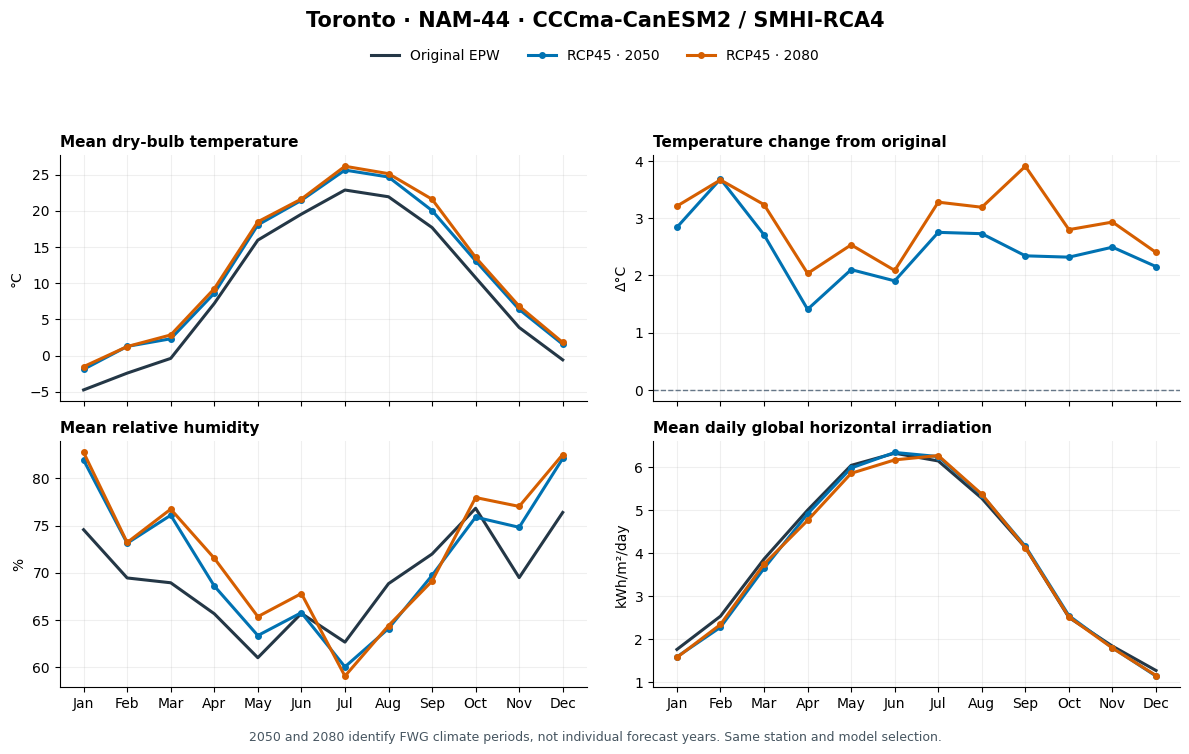

,Annual mean temperature (°C),Change from original (°C)
Original EPW,9.36,0.00
RCP45 · 2050,11.81,2.45
RCP45 · 2080,12.30,2.94


In [14]:
compare_climates(
    FWG_EPW_DIR / "NAM-44.epw", sorted((FWG_OUTPUT_DIR / "regional-direct/NAM-44").glob("*.epw")),
    "Toronto · NAM-44 · CCCma-CanESM2 / SMHI-RCA4", "toronto-climate-comparison",
)
